## Lab 4: FIR filters and envelopes

The goal of this lab is to connect the FIR filter ideas from the theory summary with the synthesis workflow from the previous labs. We will study two related ideas:

- a finite impulse response (FIR) filter as a weighted sum of past samples, and
- an envelope detector built from a rectifier followed by smoothing.

The theory summary on FIR filters introduces the key concepts behind convolution, impulse response, and the low-pass effect of a moving-average filter. The exercises below are designed to make those ideas concrete in both a toy example and in audio signals.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

from util import load_audio, plot_spectrogram

### 1. FIR filters as weighted sums

An FIR filter computes the output as

$$
y[n] = \sum_{k=0}^{M} b_k x[n-k]
$$

where the coefficients $b_k$ define the filter. In the special case of a moving-average filter, all coefficients are equal to $1/(M+1)$ so the output is the average of $M+1$ input samples. This is exactly the operation implemented by convolution with an impulse response that is a short rectangular pulse.

A useful way to think about this is: the filter output at each instant is a local average of the input, so sharp changes get smoothed. That is why a moving-average filter is often used as a simple low-pass filter.

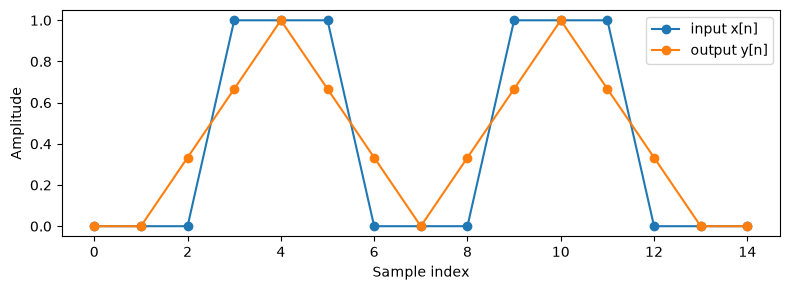

In [2]:
fs = 1
x = np.array([0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0], dtype=float)
b = np.array([1/3, 1/3, 1/3])
y = np.convolve(b, x, mode='same')

plt.figure(figsize=(8, 3))
plt.plot(x, 'o-', label='input x[n]')
plt.plot(y, 'o-', label='output y[n]')
plt.xlabel('Sample index')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

#### 1.1 Questions

1. Which parts of the signal become smoother after filtering?
2. Why does the filtered output change more gradually than the original input?
3. What would happen to the smoothing effect if the filter used more coefficients?


1. las subidas, es decir, las partes entre 0 y 1, se hacen mas suaves, ya que se calcula la media. los coefeic donde tanto ellos como dos anteriores son 1, siguen en 1
2. porque se hace el valor medio entre los distintos puntos, incluido el de la salida. esto hace que los valores vayan en recta menos pronunciada
3. seria menos pronunciada, ya que empezaría antes y acabaría más tarde

#### 1.2 Implement an averaging filter
Complete the function below so that it applies an $N$-point moving-average filter with `np.convolve` and returns a result with the same length as the input. Try different values of $N$.

In [3]:
def averaging_filter(x, N):
    x = np.asarray(x, dtype=float)
    b = np.ones(N) / N
    return np.convolve(x, b, mode='same')

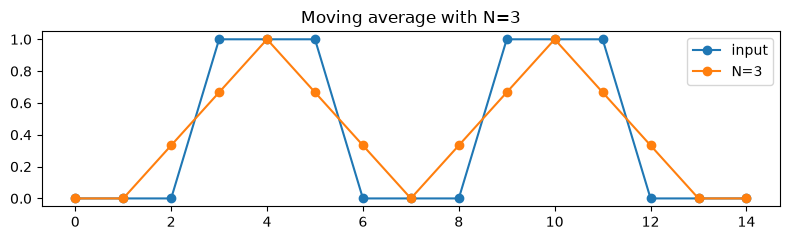

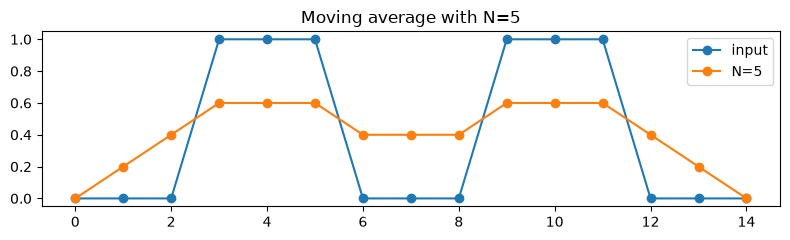

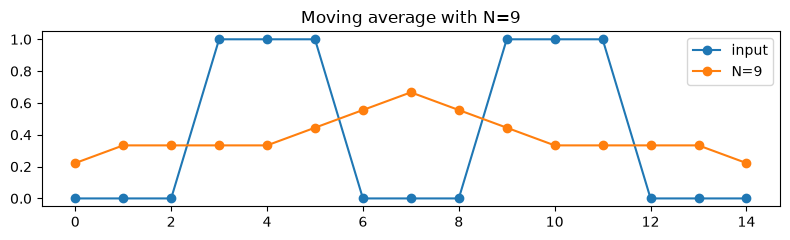

In [8]:
for N in [3, 5, 9]:
    y_N = averaging_filter(x, N)
    plt.figure(figsize=(8, 2.5))
    plt.plot(x, 'o-', label='input')
    plt.plot(y_N, 'o-', label=f'N={N}')
    plt.title(f'Moving average with N={N}')
    plt.legend()
    plt.tight_layout()
    plt.show()

#### 1.3 Questions

1. What happens to the output when $N$ becomes larger?
   - Answer: write your response here.

2. Why does the filter behave like a low-pass filter?
   - Answer: write your response here.

3. Which frequencies are attenuated more strongly: low frequencies or high frequencies? [note: be careful because we are visualizing time-domain]
   - Answer: write your response here.

1. el output es más suave, es decir, con unas pendientes menos pronunciadas y unos picos más bajos o suaves
2. porque para una N grande, los picos de corta duracion se hacen más suaves, es decir, se evitan los agudos repentinos.
3. las frecuencias altas se suavizan más fuertemente, ya que se está haciendo una media, y los valores altos están alejados de la media al haber más valores bajos que altos. 

1. los cambios son mas suaves, es decir, hay menos cambio repentino en la amplitud de las frecuencias. 
2. porque se evitan las Ampltiudes lejos de la media del contexto, es decir, se atenuan frecuencias con amplitud más baja que la media y lo mismo con amplitud más alta que la media
3. las frecuencias con amplitud alta, no tiene nada que ver con esto. 

1. se hace un output as suave, menos cambio repentino en amplitud
2. porque, para frecuencias altas, habrá un cambio rápido en amplitud. este filtro, al hacer un average, está atenuando estos cambios rápidos en amplitud. por tanto, las frecuencias altas se suavizan.
3. las frecuencias altas se atenuan más fuertemente, ya que presentan cambios repentinos en la amplitud

### 2. Envelope detection with rectification and smoothing
An detector uses two blocks:
1. a full-wave rectifier, implemented with `np.abs(x)`, and
2. a smoothing filter, implemented with the averaging filter from above.

The rectifier removes the sign of the signal, turning oscillations into a positive waveform. The averaging stage then removes the rapid oscillations and keeps the slower rise and fall of the envelope.

#### 2.1 Add envelope detector
Modify the following functions to try a few different values of $N$ and compare the resulting envelope.

In [9]:
def envelope(x, N):
    x = np.asarray(x, dtype=float)
    rectified = np.abs(x)
    return averaging_filter(rectified, N)

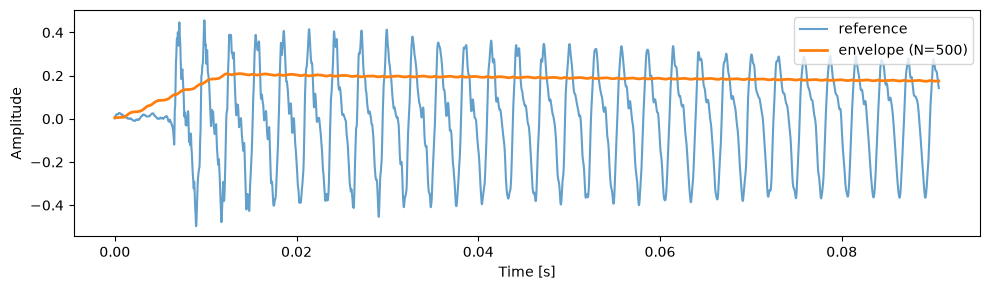

In [19]:
reference_audio, fs = load_audio('audio/reference.wav')
t = np.arange(len(reference_audio)) / fs

N = 500
env = envelope(reference_audio, N)

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], reference_audio[:4000], alpha=0.7, label='reference')
plt.plot(t[:4000], env[:4000], linewidth=2, label=f'envelope (N={N})')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

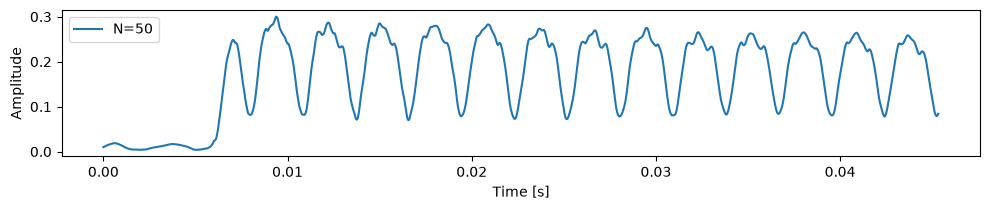

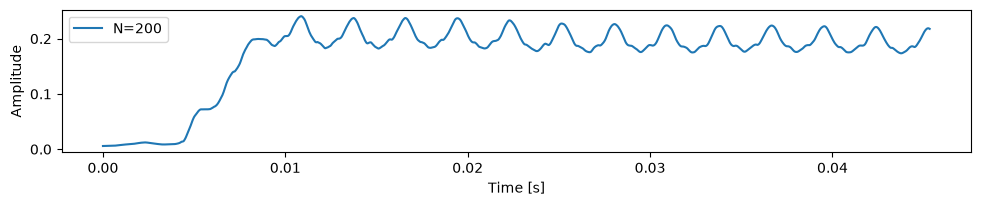

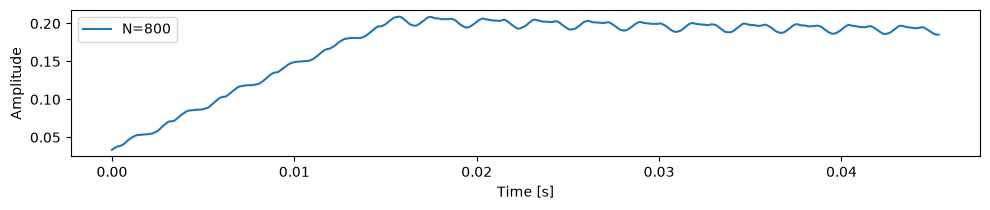

In [16]:
# Try a few filter sizes and inspect how the envelope changes
for N in [50, 200, 800]:
    env_N = envelope(reference_audio, N)
    plt.figure(figsize=(10, 2.2))
    plt.plot(t[:2000], env_N[:2000], label=f'N={N}')
    plt.xlabel('Time [s]')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.tight_layout()
    plt.show()

# Try adding one or two more values of N here to see how the smoothing changes
# for example: [25, 100, 400, 1600]


#### 2.2 Questions

1. Why does the rectifier make the envelope easier to estimate?
   - Answer: write your response here.

2. What happens if $N$ is very small?
   - Answer: write your response here.

3. What happens if $N$ is very large?
   - Answer: write your response here.

1. el valor absoluto hace que se pueda calcular mejor la envolvente ya que solo se considera la amplitud de la señal en ese momento, y no si es negativa o positiva, ya que al final el oído humano identifica el valor absoluto.
2. si N es muy pequeña, el filtro enveloping, que sigue la evolucion de la amplitud, lo hace ' a corto plazo ', es decir, que no muestra como evoluciona en general sino que un intervalo mas pequeño
3. si N es muy grande, el filtro funcionará como una muestra de la evolucion de la amplitud en el tiempo

1. el valor absolutoelimina el signo de la señal, evitando que las amplitudes negativas y positivas se cancelen, para mostrar únicamente el promedio en amplitud absoluta 
2. para mayor N , la envolvente queda más suave, ya que usa más muestras para calcular la media, pero se pueden perder detalles de cambios de amplitud pronunciados, ya que se aplica un filtro general. para una N más pequeña, se pierde esta característica de mostrar los cambios a largo plazo pero no se pierden tantos detalles. 

### 3. Apply the envelope to a synthesized sound

Now we combine the harmonic synthesis idea from Lab 3 with the envelope detector from this lab. The goal is to make the synthesized signal look and sound more like the reference by multiplying the harmonic signal by a slowly varying envelope. Add the amplitude weights obtained in Lab 3.

#### 3.1 Add envelope

Add your own amplitude weights in the code cell below and try at least two different values of the smoothing window $N$.
You can compare how the synthesized sound changes when the envelope is smoother or less smooth.


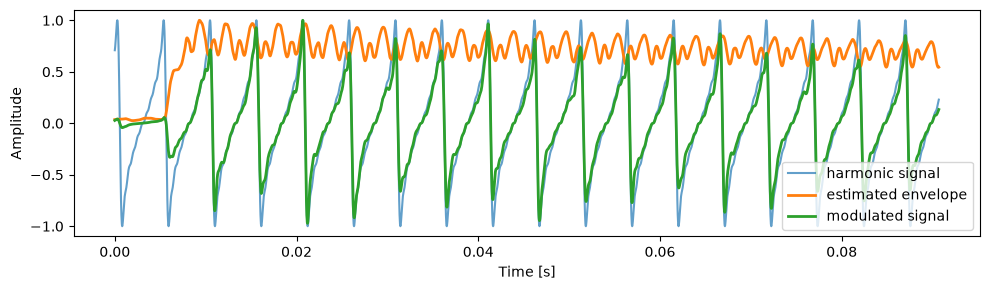

In [23]:
def synthesize(f0, phi, Ak, t):
    y = np.zeros_like(t, dtype=float)
    for k in range(1, len(Ak) + 1):
        y += Ak[k - 1] * np.cos(2 * np.pi * k * f0 * t + k * phi - (k - 1) * np.pi / 2)
    return y

fs = 44100
duration = 3.0
f0 = 196.0  # Nota G3 (Sol)
phi = 0.9
# add your own amplitude weights
weights = [1.0, 0.65, 0.45, 0.35, 0.25,
           0.18, 0.13, 0.10, 0.07, 0.05]
t = np.arange(len(reference_audio)) / fs

harmonic_signal = synthesize(f0, phi, weights, t)
harmonic_signal = harmonic_signal / np.max(np.abs(harmonic_signal))

# try different values of N
N = 100
envelope_signal = envelope(reference_audio, N)
envelope_signal = envelope_signal / np.max(np.abs(envelope_signal))

modulated_signal = harmonic_signal * envelope_signal
modulated_signal = modulated_signal / np.max(np.abs(modulated_signal))

plt.figure(figsize=(10, 3))
plt.plot(t[:4000], harmonic_signal[:4000], alpha=0.7, label='harmonic signal')
plt.plot(t[:4000], envelope_signal[:4000], linewidth=2, label='estimated envelope')
plt.plot(t[:4000], modulated_signal[:4000], linewidth=2, label='modulated signal')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.tight_layout()
plt.show()

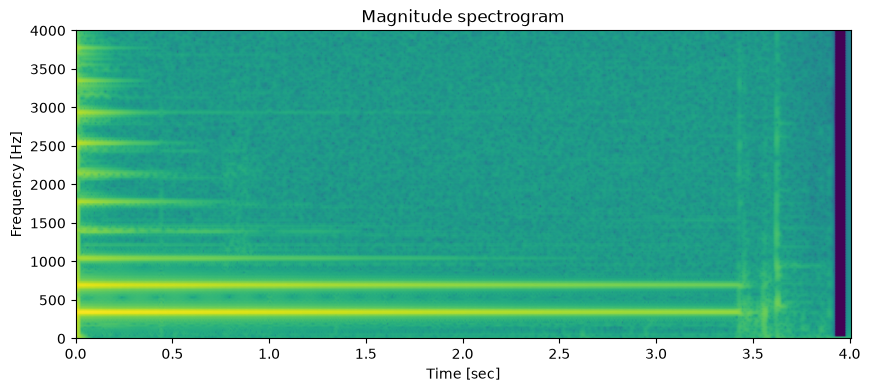

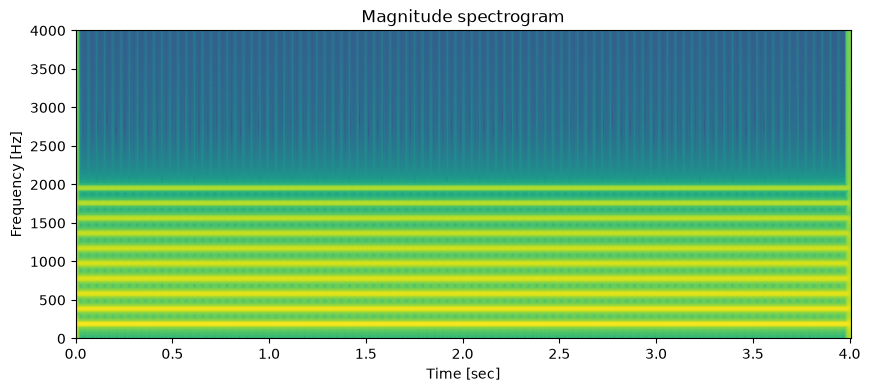

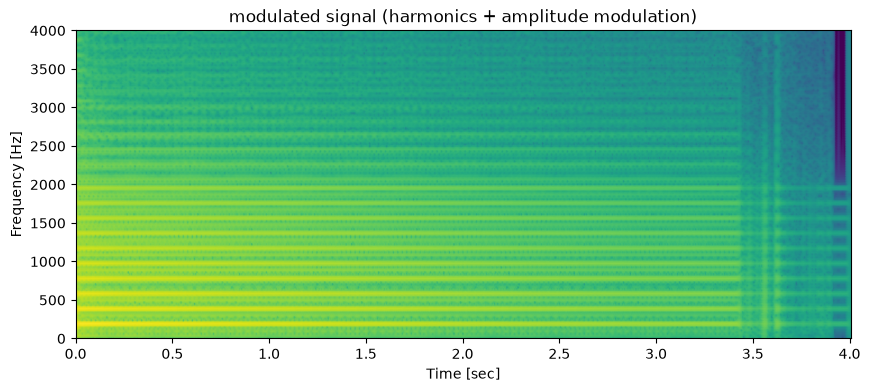

In [24]:
# The envelope introduces amplitude modulation, so the modulated signal will show more structure than a pure harmonic tone.
ax1 = plot_spectrogram(reference_audio, sr=fs, N=2048, H=256)
ax2 = plot_spectrogram(harmonic_signal, sr=fs, N=2048, H=256)
ax3 = plot_spectrogram(modulated_signal, sr=fs, N=2048, H=256)

ax1.set_ylim([0, 4000])
ax2.set_ylim([0, 4000])
ax3.set_ylim([0, 4000])
ax3.set_title('modulated signal (harmonics + amplitude modulation)')
plt.show()


In [25]:
from IPython.display import Audio, display

print("Reference sound")
display(Audio(reference_audio, rate=fs))

print("Harmonic sound")
display(Audio(harmonic_signal, rate=fs))

print("Modulated sound")
display(Audio(modulated_signal, rate=fs))


Reference sound


Harmonic sound


Modulated sound


#### 3.2 Questions

1. How does the envelope change the amplitude of the sound over time?
   - Answer: write your response here.

2. What is the main difference between the spectrogram of the pure harmonic signal and the spectrogram of the modulated signal?
   - Answer: write your response here.

3. Why does the modulated signal show more structure than the purely harmonic signal?
   - Answer: write your response here.

4. Why is the smoothing stage important for creating a realistic amplitude envelope?
   - Answer: write your response here.

1. el envolvente cambia la amplitud del sonido porque se multiplica el señal armonico sintetizado por el envolvente, que es la evolucion que tienen las amplitudes a lo largo del tiempo. esto hace que la amplitud del modulado se aproxime a la amplitud del original. 
2. que el puro tiene una amplitud constante, y el modulado muestra cambio en las ampltiudes. 
3. porque tambien se han tenido en cuenta los cambios en amplitud
4. porque según como se haga, hará que la amplitud se modifique de forma similar a la del sonido original o no 

4. suavizamos el valor absoluto para calcular como evoluciona la señal input, ignorando cambios repentinos. no seguir cada variacion individual nos ayuda a mostrar la misma evolucion 